# 21 - Team strength (experiment 11)

Idea Q1 in `EXPERIMENTS.md`. **Teams repeat across battles**: the 10,000 training battles
use only about 4,200 distinct P1 teams, P2's teams come from the same pool, and the win rate depends on the team, in large part through how rare it is (a P1 team that appears only once wins about 40% of its battles). The win rate of a team, estimated on the training battles, is information the turn-30 state does not
contain: its partial correlation with the winner given all 155 v1 features is about 0.11, while every candidate of
experiments 05-09 stayed at 0.04 or below.

`TeamStrengthEncoder` (`src/team_strength.py`) is the first step of the pipeline, so it is fitted on the training
part of each fold only; inside it, every training row is encoded from the other inner folds (cross-fitting), so no
row ever sees its own label.

| Section | Content |
|---|---|
| 1 | Descriptive: how often teams repeat, spread of the team win rates |
| 2 | Paired repeated CV: v1 vs v1 + team strength (LightGBM, LogReg), robust subset, variants of the encoder |
| 3 | Leakage checks: shuffled team keys (the gain must disappear); CV grouped by P1 team |
| 4 | Stress test: a share of the validation teams marked as never seen (as on a private set with other teams) |
| 5 | Summary table and decision |

**Decision rule (fixed before running):** adopt if the gain is **≥ +0.5 points** with **≥ 11 of 15 folds** improved,
the shuffled-keys control gains nothing, and with **100% unseen teams** the accuracy is not more than 0.1 points
below the baseline (the feature must not hurt where it cannot help).

## 0. Setup

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import robust_columns, team_key_features
from src.models import get_model_specs, with_params
from src.team_strength import KEY_P1, KEY_P2, TeamStrengthEncoder, mask_teams, with_team_strength
from src.validation import REPEAT_SEEDS, SEED, augmented_cv_scores, perturb_p2_ko

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 250)
PROC = ROOT / "data" / "processed"
OUT = PROC / "models"
OUT.mkdir(parents=True, exist_ok=True)

team, states = [pd.read_pickle(PROC / f"{name}_train.pkl") for name in ("team", "states")]
ref = pd.read_pickle(PROC / "features_train.pkl")             # v1 features (notebook 03)
with open(PROC / "feature_groups.json") as f:
    groups = json.load(f)
y = ref.pop("player_won")
NUM = [c for c in ref.columns if c not in groups["species_cat"]]
ROBUST = robust_columns(NUM)
KEYS = [KEY_P1, KEY_P2]

keys = team_key_features(team, states).reindex(ref.index)
assert keys.notna().all().all()
X = pd.concat([ref[NUM], keys], axis=1)
print(f"battles: {len(X):,} | v1 features: {len(NUM)} | robust: {len(ROBUST)}")

specs = get_model_specs()
MODELS = {
    "lightgbm": with_params(specs["lightgbm"], {
        "model__colsample_bytree": 0.6286197472598067, "model__learning_rate": 0.006552992991573526,
        "model__min_child_samples": 106, "model__n_estimators": 1424, "model__num_leaves": 12,
        "model__reg_alpha": 0.6070874110546393, "model__reg_lambda": 2.7129089558470034,
        "model__subsample": 0.6629794526009424}),
    "logreg": with_params(specs["logreg"], {"model__C": 0.006690421166498805}),
}

battles: 10,000 | v1 features: 155 | robust: 145


## 1. How often teams repeat

distinct P1 teams: 4,167 | battles whose P1 team appears more than once: 6,870 | most frequent team: 195 battles
battles with all 6 P2 Pokémon revealed: 5,557 | of these, P2 team equal to some P1 team: 71.2%
revealed P2 Pokémon per battle: {1: 17, 2: 39, 3: 165, 4: 849, 5: 3373, 6: 5557}
teams with >= 30 battles: 38 | sd of their win rates: 0.098 | expected from noise only: 0.071


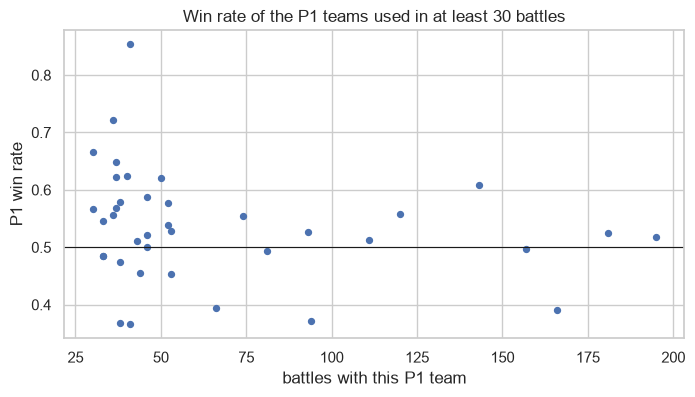

In [2]:
p1_counts = keys[KEY_P1].value_counts()
n_p2 = keys[KEY_P2].str.count(r"\|") + 1
full_p2 = keys.loc[n_p2 == 6, KEY_P2]
print(f"distinct P1 teams: {p1_counts.size:,} | battles whose P1 team appears more than once: "
      f"{int(p1_counts[p1_counts > 1].sum()):,} | most frequent team: {p1_counts.iloc[0]} battles")
print(f"battles with all 6 P2 Pokémon revealed: {len(full_p2):,} | of these, P2 team equal to some P1 team: "
      f"{full_p2.isin(set(keys[KEY_P1])).mean():.1%}")
print(f"revealed P2 Pokémon per battle: {n_p2.value_counts().sort_index().to_dict()}")

# Spread of the win rates of frequent teams vs the spread expected from binomial noise alone
win = y.groupby(keys[KEY_P1]).agg(["mean", "size"])
frequent = win[win["size"] >= 30]
expected = np.sqrt((0.25 / frequent["size"]).mean())
print(f"teams with >= 30 battles: {len(frequent)} | sd of their win rates: {frequent['mean'].std():.3f} "
      f"| expected from noise only: {expected:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(frequent["size"], frequent["mean"], s=18)
ax.axhline(0.5, c="k", lw=0.8)
ax.set_xlabel("battles with this P1 team")
ax.set_ylabel("P1 win rate")
ax.set_title("Win rate of the P1 teams used in at least 30 battles")
plt.show()

## 2. Paired repeated CV

Every configuration is scored on the same 15 folds (seeds 42 / 7 / 123 × 5) as its baseline; the encoder is refitted
inside every fold. Encoder variants: smoothing K = 10 (default), K = 30, and without the pooled P2 teams.

In [3]:
score_cache = {}

def scores(key, model, X_, val_transform=None):
    if key not in score_cache:
        score_cache[key] = np.concatenate([augmented_cv_scores(model, X_, y, seed=s, val_transform=val_transform)
                                           for s in REPEAT_SEEDS])
    return score_cache[key]

results = []

def compare(model_name, config, base_key, base_model, base_X, model, X_, val_transform=None):
    base = scores((model_name, base_key), base_model, base_X)
    cand = scores((model_name, config), model, X_, val_transform)
    d = cand - base
    row = {"model": model_name, "config": config, "baseline config": base_key, "mean": cand.mean(),
           "baseline": base.mean(), "gain (points)": d.mean() * 100, "std of gain": d.std() * 100,
           "folds improved": int((d > 0).sum())}
    results.append(row)
    print(f"{model_name:8s} {config:34s}: {row['mean']:.4f} vs {row['baseline']:.4f} "
          f"(gain {row['gain (points)']:+.2f} ± {row['std of gain']:.2f}, {row['folds improved']}/15 folds)")
    return row

t0 = time.time()
for m in MODELS:
    compare(m, "v1 + team strength", "v1", MODELS[m], X[NUM], with_team_strength(MODELS[m]), X[NUM + KEYS])
compare("lightgbm", "robust + team strength", "robust", MODELS["lightgbm"], X[ROBUST],
        with_team_strength(MODELS["lightgbm"]), X[ROBUST + KEYS])
compare("lightgbm", "v1 + team strength (K=30)", "v1", MODELS["lightgbm"], X[NUM],
        with_team_strength(MODELS["lightgbm"], smoothing=30.0), X[NUM + KEYS])
compare("lightgbm", "v1 + team strength (not pooled)", "v1", MODELS["lightgbm"], X[NUM],
        with_team_strength(MODELS["lightgbm"], pooled=False), X[NUM + KEYS])
print(f"done in {time.time() - t0:.0f}s")

lightgbm v1 + team strength                : 0.6869 vs 0.6779 (gain +0.90 ± 0.65, 14/15 folds)
logreg   v1 + team strength                : 0.6801 vs 0.6750 (gain +0.51 ± 0.45, 13/15 folds)
lightgbm robust + team strength            : 0.6859 vs 0.6782 (gain +0.77 ± 0.50, 15/15 folds)
lightgbm v1 + team strength (K=30)         : 0.6868 vs 0.6779 (gain +0.89 ± 0.55, 15/15 folds)
lightgbm v1 + team strength (not pooled)   : 0.6839 vs 0.6779 (gain +0.60 ± 0.69, 11/15 folds)
done in 81s


In [4]:
# What the encoder produces on the whole train (descriptive; cross-fitted, so no row sees its own label)
enc = TeamStrengthEncoder().fit_transform(X[NUM + KEYS], y)
te = enc[["te_p1", "te_p2", "te_n_p1", "te_n_p2", "diff_te"]]
display(pd.DataFrame({"mean": te.mean(), "std": te.std(), "corr with winner": te.corrwith(y)}).round(3))
oof_path = PROC / "oof_lgbm.pkl"
if oof_path.exists():
    residual = pd.read_pickle(oof_path)["residual"].reindex(X.index)
    print("corr with the residual of the v1 LightGBM (noise ~0.02):", te.corrwith(residual).round(3).to_dict())

,mean,std,corr with winner
te_p1,0.505,0.062,0.109
te_p2,0.504,0.061,-0.085
te_n_p1,2.037,1.857,0.062
te_n_p2,2.602,2.172,-0.080
diff_te,0.001,0.088,0.136


corr with the residual of the v1 LightGBM (noise ~0.02): {'te_p1': 0.079, 'te_p2': -0.064, 'te_n_p1': 0.032, 'te_n_p2': -0.043, 'diff_te': 0.1}


## 3. Leakage checks

- **Shuffled keys:** the team keys are permuted across battles (the link between a battle and its team is broken,
  the distribution of the keys is kept). If the gain of section 2 came from a leak in the encoder rather than from
  the teams, it would survive; it must disappear.
- **CV grouped by P1 team** (`StratifiedGroupKFold`, seed 42): validation battles never share their P1 team with the
  training battles. **Correction:** `te_p1` does not always fall back to the prior. About 60% of the validation
rows still get an informative value, because a team can enter the pool through the fully revealed P2 teams.
So this result is **not** a pure unseen-team number.

In [5]:
rng = np.random.default_rng(SEED)
X_shuffled = X.copy()
X_shuffled[KEYS] = X[KEYS].to_numpy()[rng.permutation(len(X))]
t0 = time.time()
compare("lightgbm", "v1 + shuffled team keys", "v1", MODELS["lightgbm"], X[NUM],
        with_team_strength(MODELS["lightgbm"]), X_shuffled[NUM + KEYS])
print(f"done in {time.time() - t0:.0f}s")

lightgbm v1 + shuffled team keys           : 0.6773 vs 0.6779 (gain -0.06 ± 0.35, 7/15 folds)
done in 12s


In [6]:
def grouped_cv(model, X_, groups_, seed=SEED):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    out = []
    for tr, va in cv.split(X_, y, groups_):
        m = clone(model).fit(X_.iloc[tr], y.iloc[tr])
        out.append((m.predict(X_.iloc[va]) == y.iloc[va].to_numpy()).mean())
    return np.array(out)

t0 = time.time()
g_base = grouped_cv(MODELS["lightgbm"], X[NUM], X[KEY_P1])
g_te = grouped_cv(with_team_strength(MODELS["lightgbm"]), X[NUM + KEYS], X[KEY_P1])
print(f"grouped by P1 team: v1 {g_base.mean():.4f} | v1 + team strength {g_te.mean():.4f} "
      f"| gain {(g_te - g_base).mean() * 100:+.2f} points, {(g_te > g_base).sum()}/5 folds ({time.time() - t0:.0f}s)")

grouped by P1 team: v1 0.6734 | v1 + team strength 0.6770 | gain +0.36 points, 4/5 folds (33s)


## 4. Stress test: teams never seen

The model is trained as usual; in the validation part a share of the battles gets the key `__unseen__`, so the
encoder gives them the prior (0.5, count 0). With 100% unseen the feature carries nothing, and the model must not do
worse than the baseline. The P2-KO stress test of the previous experiments is repeated as well.

In [7]:
t0 = time.time()
model_te = with_team_strength(MODELS["lightgbm"])
stress = {"v1 (baseline)": {"clean": scores(("lightgbm", "v1"), MODELS["lightgbm"], X[NUM]).mean()}}
row = {"clean": scores(("lightgbm", "v1 + team strength"), model_te, X[NUM + KEYS]).mean()}
for frac in (0.3, 0.6, 1.0):
    row[f"{frac:.0%} unseen"] = compare("lightgbm", f"v1 + team strength, {frac:.0%} unseen", "v1",
                                        MODELS["lightgbm"], X[NUM], model_te, X[NUM + KEYS],
                                        val_transform=lambda v, f=frac: mask_teams(v, f, SEED))["mean"]
for f in (0.5, 1.0):
    row[f"p2_ko_fixed_{f:g}"] = augmented_cv_scores(model_te, X[NUM + KEYS], y, seed=SEED,
                                                    val_transform=lambda v, f=f: perturb_p2_ko(v, f, SEED)).mean()
stress["v1 + team strength"] = row
print(f"done in {time.time() - t0:.0f}s")
pd.DataFrame(stress).T.round(4)

lightgbm v1 + team strength, 30% unseen    : 0.6808 vs 0.6779 (gain +0.29 ± 0.57, 12/15 folds)
lightgbm v1 + team strength, 60% unseen    : 0.6764 vs 0.6779 (gain -0.15 ± 0.55, 6/15 folds)
lightgbm v1 + team strength, 100% unseen   : 0.6720 vs 0.6779 (gain -0.59 ± 0.51, 2/15 folds)
done in 41s


,clean,30% unseen,60% unseen,100% unseen,p2_ko_fixed_0.5,p2_ko_fixed_1
v1 (baseline),0.6779,NaN,NaN,NaN,NaN,NaN
v1 + team strength,0.6869,0.6808,0.6764,0.672,0.69,0.6899


## 5. Summary table and decision

Rule fixed before running: gain ≥ +0.5 points with ≥ 11/15 folds; shuffled keys must gain nothing; with 100% unseen
teams no more than 0.1 points below the baseline.

In [8]:
summary = pd.DataFrame(results).drop_duplicates(["model", "config"])
summary.to_csv(OUT / "team_strength.csv", index=False)

def gain(config):
    return summary.loc[(summary["model"] == "lightgbm") & (summary["config"] == config), "gain (points)"].iloc[0]

main = summary[(summary["model"] == "lightgbm") & (summary["config"] == "v1 + team strength")].iloc[0]
checks = {
    "gain >= +0.5 points": main["gain (points)"] >= 0.5,
    "folds improved >= 11/15": main["folds improved"] >= 11,
    "shuffled keys gain < +0.2 points": gain("v1 + shuffled team keys") < 0.2,
    "100% unseen >= baseline - 0.1 points": gain("v1 + team strength, 100% unseen") >= -0.1,
}
display(summary.round(4))
for k, v in checks.items():
    print(f"{'OK ' if v else 'NO '} {k}")
print("ADOPT" if all(checks.values()) else "DO NOT ADOPT")

,model,config,baseline config,mean,baseline,gain (points),std of gain,folds improved
0,lightgbm,v1 + team strength,v1,0.6869,0.6779,0.9033,0.6510,14
1,logreg,v1 + team strength,v1,0.6801,0.6750,0.5067,0.4453,13
2,lightgbm,robust + team strength,robust,0.6859,0.6782,0.7700,0.5019,15
3,lightgbm,v1 + team strength (K=30),v1,0.6868,0.6779,0.8933,0.5531,15
4,lightgbm,v1 + team strength (not pooled),v1,0.6839,0.6779,0.6033,0.6896,11
5,lightgbm,v1 + shuffled team keys,v1,0.6773,0.6779,-0.0633,0.3514,7
6,lightgbm,"v1 + team strength, 30% unseen",v1,0.6808,0.6779,0.2933,0.5656,12
7,lightgbm,"v1 + team strength, 60% unseen",v1,0.6764,0.6779,-0.1500,0.5529,6
8,lightgbm,"v1 + team strength, 100% unseen",v1,0.6720,0.6779,-0.5900,0.5135,2


OK  gain >= +0.5 points
OK  folds improved >= 11/15
OK  shuffled keys gain < +0.2 points
NO  100% unseen >= baseline - 0.1 points
DO NOT ADOPT


## 6. An encoder that does not hurt on teams never seen

Sections 2-4: the team strength gains **+0.90 points** (14/15 folds), the shuffled-keys control gains nothing and
the grouped CV keeps +0.36 (not a pure unseen-team number, see section 3), so the signal is real. But with **100% unseen teams the model loses 0.59 points**: in
training, "prior 0.5 with count 0" only happens for teams that appear once, so the model learns that it means a
*rare* team and applies that to every unseen team.

Two changes to `TeamStrengthEncoder` (`src/team_strength.py`), both decided before looking at these results:
- `counts=False`: drop `te_n_p1` / `te_n_p2`, the most direct signal of "rare team";
- `train_unseen`: a random share of the **training** rows gets the unseen values (prior, count 0), like dropout, so
  "unseen" no longer means "rare" and the model learns to predict without the team information.

Same rule as section 5: gain ≥ +0.5 with ≥ 11/15 folds, and with 100% unseen teams ≥ baseline - 0.1 points. Among the
configurations that pass, the one with the largest clean gain is chosen.

In [9]:
ENCODERS = {
    "no counts": dict(counts=False),
    "train unseen 30%": dict(train_unseen=0.3),
    "no counts + train unseen 30%": dict(counts=False, train_unseen=0.3),
    "no counts + train unseen 50%": dict(counts=False, train_unseen=0.5),
}
t0 = time.time()
robust_rows = []
for name, params in ENCODERS.items():
    model_v = with_team_strength(MODELS["lightgbm"], **params)
    r = {"encoder": name}
    r["clean"] = compare("lightgbm", f"v1 + team strength [{name}]", "v1", MODELS["lightgbm"], X[NUM],
                         model_v, X[NUM + KEYS])
    for frac in (0.6, 1.0):
        r[f"{frac:.0%} unseen"] = compare("lightgbm", f"v1 + team strength [{name}], {frac:.0%} unseen", "v1",
                                          MODELS["lightgbm"], X[NUM], model_v, X[NUM + KEYS],
                                          val_transform=lambda v, f=frac: mask_teams(v, f, SEED))
    robust_rows.append({"encoder": name, "gain clean": r["clean"]["gain (points)"],
                        "folds improved": r["clean"]["folds improved"],
                        "gain 60% unseen": r["60% unseen"]["gain (points)"],
                        "gain 100% unseen": r["100% unseen"]["gain (points)"]})
print(f"done in {time.time() - t0:.0f}s")

default = summary[summary["model"] == "lightgbm"].set_index("config")
robust_rows.insert(0, {"encoder": "default (section 2)",
                       "gain clean": default.loc["v1 + team strength", "gain (points)"],
                       "folds improved": default.loc["v1 + team strength", "folds improved"],
                       "gain 60% unseen": default.loc["v1 + team strength, 60% unseen", "gain (points)"],
                       "gain 100% unseen": default.loc["v1 + team strength, 100% unseen", "gain (points)"]})
enc_table = pd.DataFrame(robust_rows).set_index("encoder")
enc_table["passes"] = ((enc_table["gain clean"] >= 0.5) & (enc_table["folds improved"] >= 11)
                       & (enc_table["gain 100% unseen"] >= -0.1))
pd.DataFrame(results).drop_duplicates(["model", "config"]).to_csv(OUT / "team_strength.csv", index=False)
enc_table.round(2)

lightgbm v1 + team strength [no counts]    : 0.6843 vs 0.6779 (gain +0.64 ± 0.57, 12/15 folds)
lightgbm v1 + team strength [no counts], 60% unseen: 0.6788 vs 0.6779 (gain +0.09 ± 0.46, 9/15 folds)
lightgbm v1 + team strength [no counts], 100% unseen: 0.6749 vs 0.6779 (gain -0.30 ± 0.46, 2/15 folds)
lightgbm v1 + team strength [train unseen 30%]: 0.6867 vs 0.6779 (gain +0.88 ± 0.58, 13/15 folds)
lightgbm v1 + team strength [train unseen 30%], 60% unseen: 0.6805 vs 0.6779 (gain +0.26 ± 0.45, 10/15 folds)
lightgbm v1 + team strength [train unseen 30%], 100% unseen: 0.6756 vs 0.6779 (gain -0.23 ± 0.37, 5/15 folds)
lightgbm v1 + team strength [no counts + train unseen 30%]: 0.6854 vs 0.6779 (gain +0.75 ± 0.60, 12/15 folds)
lightgbm v1 + team strength [no counts + train unseen 30%], 60% unseen: 0.6800 vs 0.6779 (gain +0.21 ± 0.44, 12/15 folds)
lightgbm v1 + team strength [no counts + train unseen 30%], 100% unseen: 0.6755 vs 0.6779 (gain -0.24 ± 0.35, 1/15 folds)
lightgbm v1 + team strength 

,gain clean,folds improved,gain 60% unseen,gain 100% unseen,passes
encoder,,,,,
default (section 2),0.90,14,-0.15,-0.59,False
no counts,0.64,12,0.09,-0.30,False
train unseen 30%,0.88,13,0.26,-0.23,False
no counts + train unseen 30%,0.75,12,0.21,-0.24,False
no counts + train unseen 50%,0.67,13,0.26,-0.11,False


In [10]:
passing = enc_table[enc_table["passes"]]
if len(passing):
    best_encoder = passing["gain clean"].idxmax()
    print(f"ADOPT encoder: {best_encoder} | parameters: {ENCODERS.get(best_encoder, {})}")
else:
    print("No encoder passes the rule: keep the experiment-04 models as the reference")

No encoder passes the rule: keep the experiment-04 models as the reference


## 7. Summary

- **Teams repeat** (section 1): 4,167 distinct P1 teams in 10,000 battles; 71% of the fully revealed P2 teams equal
  some P1 team; the win rates of frequent teams spread more than noise allows (sd 0.098 vs 0.071).
- **Gain** (section 2): LightGBM +0.90 points (0.6779 → 0.6869, 14/15 folds), robust subset +0.77 (15/15), LogReg
  +0.51 (13/15). The largest gain of all experiments (the previous ones stayed within ±0.2).
- **No leak** (section 3): with shuffled team keys the gain disappears (-0.06); with folds grouped by P1 team +0.36
  remains, but this is not a pure unseen-team number: about 60% of the validation rows still get an informative
  `te_p1` through the pooled P2 teams.
- **Teams never seen** (section 4): the default encoder loses 0.59 points when all validation teams are new: the
  model learned that "prior with count 0" means a rare team.
- **Encoder variants** (section 6): marking part of the training rows as unseen keeps the gain and reduces the
  damage: `train_unseen=0.3` +0.88 clean, +0.26 with 60% unseen, -0.23 with 100% unseen; `counts=False,
  train_unseen=0.5` +0.67 clean, +0.26 / -0.11. No variant meets the rule fixed in advance (≥ -0.10 with 100% unseen);
  the safest misses it by 0.01 points, well inside the noise (std of the gain 0.25).

**Decision.** By the rule, not adopted as the reference. The gain is real and large on data that shares our team pool
(the test set shares about 70% of the P1 teams), the risk is a private set with mostly new teams. Team decision:
use it in submissions 22-24 (main: `train_unseen=0.3`; prudent: `counts=False, train_unseen=0.5`) and keep the
experiment-04 prudent submission among the final three as the hedge against a different team pool.